In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'matplotlib'

Load The Dataset


In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

df=pd.read_csv(os.path.join(path,"AB_NYC_2019.csv"))
df.head()

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [ ]:
df.shape

(48895, 16)

3. Exploratory Data Analysis(EDA)

3.1 Missing Values

In [ ]:
missing= df.isnull().sum()
missing[missing>0]

,0
name,16
host_name,21
last_review,10052
reviews_per_month,10052


3.2 Target Variable -- room_type

<Axes: xlabel='room_type', ylabel='count'>

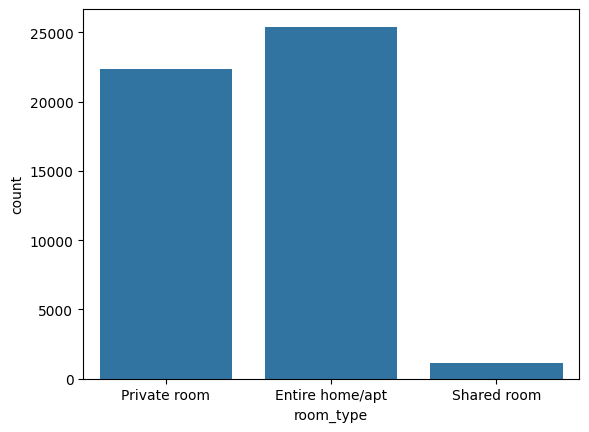

In [ ]:
df['room_type'].value_counts()
sns.countplot(x='room_type',data=df)

The classes are imbalanced-> Shared room is a Small Minority

3.3 Univariate Analysis -- Numeric Features

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

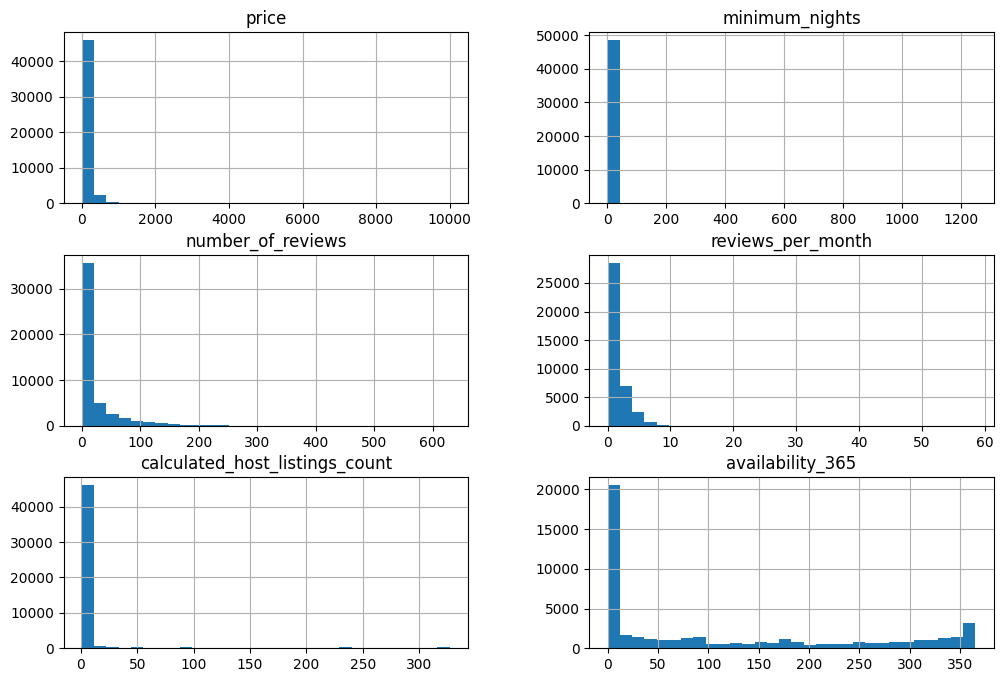

In [ ]:
numerical_cols = ["price","minimum_nights","number_of_reviews","reviews_per_month","calculated_host_listings_count","availability_365"]
df[numerical_cols].hist(bins=30, figsize=(12,8))

3.4 Univariate Analysis -- Categorical Features

<Axes: xlabel='neighbourhood_group', ylabel='count'>

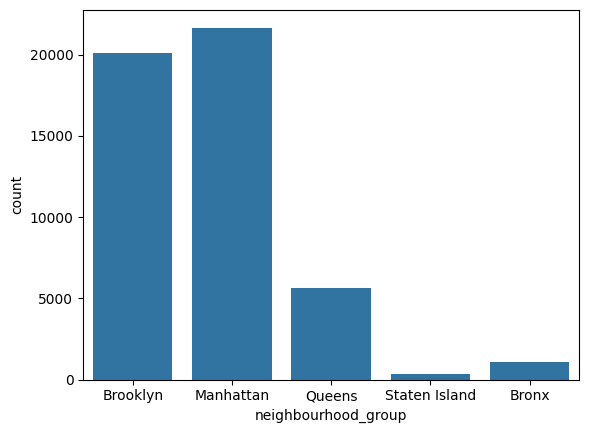

In [ ]:
sns.countplot(data=df,x='neighbourhood_group')

3.5 Bivariate Analysis-- Features vs Target

<Axes: xlabel='room_type', ylabel='price'>

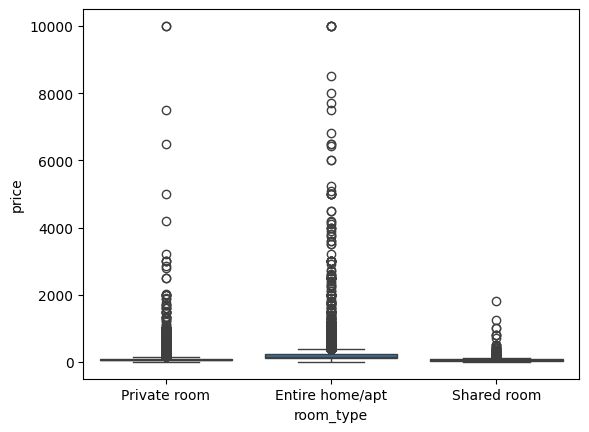

In [ ]:
sns.boxplot(x='room_type',y='price',data=df)

3.6 Correlation Between Numeric Features

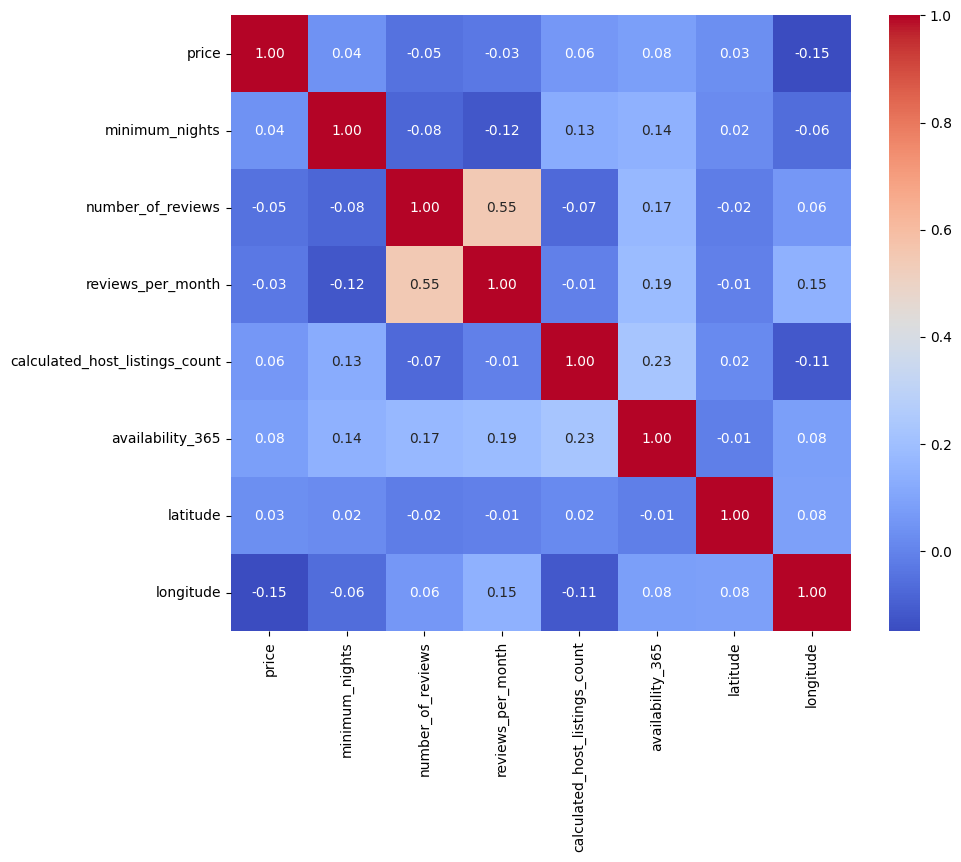

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure df is defined in the current session
if 'df' not in locals():
    import kagglehub
    path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
    df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))

# Ensure numerical_cols is defined
if 'numerical_cols' not in locals():
    numerical_cols = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month", "calculated_host_listings_count", "availability_365"]

# Calculate correlation and plot heatmap
corr = df[numerical_cols + ['latitude', 'longitude']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

3.7 Geographical Distribution(Bonus Visual)

<Axes: xlabel='longitude', ylabel='latitude'>

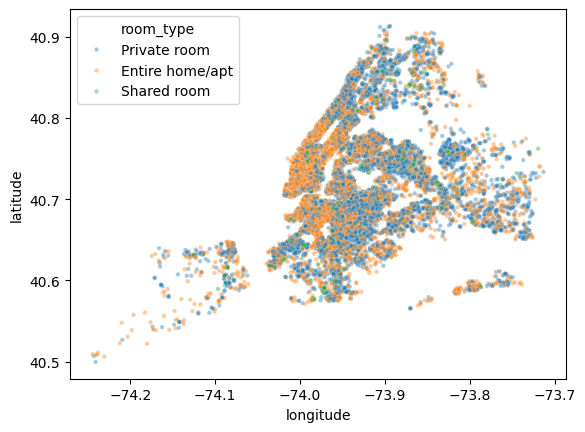

In [ ]:
sns.scatterplot(x='longitude', y='latitude',data=df,hue='room_type',alpha=0.4,s=10)

4. Data Cleaning & Feature Engineering

In [ ]:
#1. Drop Columns that don't help us.
df_clean = df.drop(columns=['id', 'name', 'host_id', 'host_name','last_review'])

#2. No reviews yet -> 0 reviews per month, not misssing
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)



In [ ]:
#3. Cap extreme outliers instead of deleting rows.

price_cap = df_clean['price'].quantile(0.99)
nights_cap = df_clean['minimum_nights'].quantile(0.99)

df_clean['price'] = df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights'] = df_clean['minimum_nights'].clip(upper=nights_cap)


In [ ]:
x=df_clean.drop(columns=['room_type'])
y=df_clean['room_type']

5. Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.33,random_state=42,stratify=y)

#Stratisfy ye ensure krta hai kinjab bhi hum split ya sample kre,har group(class) ka original proportion maintain rahe


6. Preprocessing:ColunmTransformer + Pipeline

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer


In [ ]:
numerical_cols = ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
categorical_cols = ['neighbourhood_group', 'neighbourhood', 'room_type']

#1. Pipeline -> for numeric columns
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('skewness', PowerTransformer(method='yeo-johnson')),
    ('scale', StandardScaler())
])

#2. Pipeline -> for categorical columns
categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numerical', numeric_pipeline, numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

preprocessor
#

NameError: name 'Pipeline' is not defined

In [ ]:
df_clean['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

8. Trying Multiple Algorithms

***SMOTE***(Synthetic Minority Oversampling)
for class imbalance
----------------------------
1.High chances of Overfitting

2. Data Leakage


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate

In [ ]:
class_weight="Balanced" tells the model to pay more attention to the minority class or rare calss (Shared Room)
but the problem is GradientBoosting doesn't supprot class weight so we left it as it is


models={
    'LogisticRegression':LogisticRegression(class_weight="balanced",random_state=42),
    'DecisionTree'      :DecisionTreeClassifier(class_weight="balanced",random_state=42),
    'RandomForest'      :RandomForestClassifier(class_weight="balanced",random_state=42),
    'GradientBoosting'  :GradientBoostingClassifier(random_state=42)
}